# 05 — Exploration statistique des données (EDA)

```text
Exploration statistique des données (énoncé §4.3) : figures + stats.json + EDA_REPORT.md.
Tout est calculé séparément pour kb / val / test afin de PROUVER que val/test sont représentatifs (ou voulus différents).
```

> Projet : étude comparative de techniques RAG pour le captioning d'images (MS COCO) — **groupe G1**. Exécuter les notebooks dans l'ordre : 00 → 01 → 01b → 02 → … → 09. Les helpers partagés sont dans `common.py`, `visual.py`, `rag_data.py`.

In [1]:
import os
# --- paramètre : "config.yaml" = vraies données COCO ; "config_test.yaml" = mini-COCO synthétique (test sans réseau)
CONFIG = os.environ.get("RAG_CONFIG", "config.yaml")
os.environ["RAG_CONFIG"] = CONFIG
print("config utilisée :", CONFIG)

config utilisée : config.yaml


## Imports et constantes

In [2]:
import math
from collections import Counter, defaultdict
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats as st
from common import get_logger, load_config, mkdirs, paths, read_jsonl, tokenize, write_json
log = get_logger("eda")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SPLIT_COL = {"kb": BLUE, "val": ORANGE, "test": AQUA}
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

### `style()`

In [3]:
def style(ax, title=None, xl=None, yl=None):
    ax.set_facecolor(SURF)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.tick_params(colors=INK2, labelsize=8, length=0)
    if title: ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    if xl: ax.set_xlabel(xl, color=INK2, fontsize=9)
    if yl: ax.set_ylabel(yl, color=INK2, fontsize=9)

### `save()`

In [4]:
def save(fig, path):
    fig.patch.set_facecolor(SURF); fig.tight_layout(); fig.savefig(path, dpi=160, facecolor=SURF); plt.close(fig)

### `js_div()`

In [5]:
def js_div(p, q):
    p, q = np.asarray(p, float) + 1e-12, np.asarray(q, float) + 1e-12
    p, q = p / p.sum(), q / q.sum(); m = 0.5 * (p + q)
    return float(0.5 * (p * np.log2(p / m)).sum() + 0.5 * (q * np.log2(q / m)).sum())

### `pos_tags()`
Distribution POS (NLTK ou spaCy). Renvoie None si aucun tagger dispo (hors-ligne).

In [6]:
def pos_tags(texts):
    """Distribution POS (NLTK ou spaCy). Renvoie None si aucun tagger dispo (hors-ligne)."""
    try:
        import nltk
        for r in ("averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "universal_tagset"):
            try: nltk.download(r, quiet=True)
            except Exception: pass
        c = Counter()
        for t in texts:
            for _, tag in nltk.pos_tag(t.split(), tagset="universal"):
                c[tag] += 1
        return dict(c)
    except Exception:
        pass
    try:
        import spacy
        nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
        c = Counter()
        for d in nlp.pipe(texts, batch_size=512):
            c.update(t.pos_ for t in d)
        return dict(c)
    except Exception:
        return None

### `main()`

In [7]:
def main():
    cfg = load_config(); p = paths(cfg); mkdirs(p)
    F = p["eda"]; F.mkdir(parents=True, exist_ok=True)
    meta = read_jsonl(p["tables"] / "metadata.jsonl")
    M = {s: [m for m in meta if m["split"] == s] for s in ("kb", "val", "test")}
    caps = {"kb": read_jsonl(p["tables"] / "kb_captions.jsonl"),
            "val": read_jsonl(p["tables"] / "eval_refs_val.jsonl"), "test": read_jsonl(p["tables"] / "eval_refs_test.jsonl")}
    imgs = pd.read_csv(p["tables"] / "images.csv"); imgs = imgs[imgs.status == "ok"]
    S = {"n_images": {s: len(M[s]) for s in M}, "n_captions": {s: len(caps[s]) for s in caps}}

    # ===== 1. classes d'objets (top 50, KB) + couverture
    cls = {s: Counter() for s in M}
    cls_img = {s: Counter() for s in M}
    for s in M:
        for m in M[s]:
            for k, v in m["category_counts"].items():
                cls[s][k] += v; cls_img[s][k] += 1
    top50 = cls["kb"].most_common(50)
    S["top50_classes_kb"] = [{"class": k, "instances": v, "images": cls_img["kb"][k]} for k, v in top50]
    S["n_classes_present"] = {s: len(cls[s]) for s in M}
    fig, ax = plt.subplots(figsize=(8.5, 8))
    ax.barh([k for k, _ in top50][::-1], [v for _, v in top50][::-1], color=BLUE, height=0.7)
    style(ax, "Top 50 classes d'objets (instances, KB) - échelle logarithmique", "instances"); ax.grid(axis="x", color=GRID, lw=.6); ax.grid(axis="y", visible=False)
    ax.set_xscale("log"); ax.tick_params(axis="y", labelsize=7)
    save(fig, F / "01_top50_classes.png")

    # ===== 2. complexité de scène
    nobj = {s: np.array([m["n_objects"] for m in M[s]]) for s in M}
    S["objects_per_image"] = {s: {"mean": float(nobj[s].mean()), "median": float(np.median(nobj[s])), "std": float(nobj[s].std()),
                                  "p90": float(np.percentile(nobj[s], 90)), "max": int(nobj[s].max())} for s in M}
    S["categories_per_image_mean"] = {s: float(np.mean([m["n_categories"] for m in M[s]])) for s in M}
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    bins = np.arange(0, min(41, nobj["kb"].max() + 2))
    for s in M:
        h, _ = np.histogram(np.clip(nobj[s], 0, bins[-1] - 1), bins=bins, density=True)
        axs[0].step(bins[:-1], h, where="post", color=SPLIT_COL[s], lw=1.8, label=f"{s} (n={len(nobj[s])}, moy={nobj[s].mean():.1f})")
    style(axs[0], "Objets par image", "nombre d'objets annotés (tronqué à 40)", "densité"); axs[0].legend(frameon=False, fontsize=8)
    order = ["simple", "medium", "complex", "crowded"]; w = 0.27
    for k, s in enumerate(M):
        c = Counter(m["complexity"] for m in M[s]); v = [c[o] / len(M[s]) for o in order]
        axs[1].bar(np.arange(4) + (k - 1) * w, v, w * 0.92, color=SPLIT_COL[s], label=s)
    axs[1].set_xticks(range(4)); axs[1].set_xticklabels(["simple\n1-2", "medium\n3-5", "complex\n6-9", "crowded\n10+"])
    style(axs[1], "Complexité de scène (part des images)"); axs[1].legend(frameon=False, fontsize=8)
    save(fig, F / "02_scene_complexity.png")
    comp_tab = np.array([[Counter(m["complexity"] for m in M[s])[o] for o in order] for s in ("kb", "test")])
    chi = st.chi2_contingency(comp_tab + 1e-9)
    S["complexity_distribution"] = {s: {o: Counter(m["complexity"] for m in M[s])[o] / len(M[s]) for o in order} for s in M}
    S["chi2_complexity_kb_vs_test"] = {"chi2": float(chi[0]), "p": float(chi[1]),
                                       "note": "écart attendu : le test est volontairement ÉQUILIBRÉ (stratifié), la KB reste naturelle"}

    # ===== 3. relations spatiales
    rel = {s: Counter() for s in M}
    for s in M:
        for m in M[s]:
            rel[s].update(r["rel"] for r in m["relations"])
    rels = ["left_of", "right_of", "above", "below", "overlapping", "inside", "contains", "on_top_of"]
    S["spatial_relations"] = {s: {r: rel[s][r] / max(1, sum(rel[s].values())) for r in rels} for s in M}
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for k, s in enumerate(M):
        ax.bar(np.arange(len(rels)) + (k - 1) * w, [S["spatial_relations"][s][r] for r in rels], w * .92, color=SPLIT_COL[s], label=s)
    ax.set_xticks(range(len(rels))); ax.set_xticklabels(rels, rotation=25, ha="right")
    style(ax, "Relations spatiales entre objets (géométrie des boîtes)", yl="part des paires"); ax.legend(frameon=False, fontsize=8)
    save(fig, F / "03_spatial_relations.png")

    # ===== 4. statistiques textuelles
    tok = {s: [tokenize(c["caption_raw"]) for c in caps[s]] for s in caps}
    lens = {s: np.array([len(t) for t in tok[s]]) for s in tok}
    vocab = {s: Counter(w for t in tok[s] for w in t) for s in tok}
    S["caption_length_tokens"] = {s: {"mean": float(lens[s].mean()), "median": float(np.median(lens[s])), "std": float(lens[s].std()),
                                      "min": int(lens[s].min()), "max": int(lens[s].max())} for s in tok}
    S["vocabulary"] = {s: {"size": len(vocab[s]), "hapax": sum(1 for v in vocab[s].values() if v == 1),
                           "type_token_ratio": len(vocab[s]) / max(1, sum(vocab[s].values())), "n_tokens": sum(vocab[s].values())} for s in tok}
    S["oov_rate_test_vs_kb"] = float(sum(v for w, v in vocab["test"].items() if w not in vocab["kb"]) / max(1, sum(vocab["test"].values())))
    S["oov_rate_val_vs_kb"] = float(sum(v for w, v in vocab["val"].items() if w not in vocab["kb"]) / max(1, sum(vocab["val"].values())))
    ks = st.ks_2samp(lens["kb"], lens["test"])
    S["ks_caption_length_kb_vs_test"] = {"stat": float(ks.statistic), "p": float(ks.pvalue)}
    S["top30_words_kb"] = vocab["kb"].most_common(30)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    b = np.arange(0, 31)
    for s in tok:
        h, _ = np.histogram(np.clip(lens[s], 0, 30), bins=b, density=True)
        axs[0].step(b[:-1], h, where="post", color=SPLIT_COL[s], lw=1.8, label=f"{s} (moy={lens[s].mean():.1f})")
    style(axs[0], "Longueur des captions", "tokens", "densité"); axs[0].legend(frameon=False, fontsize=8)
    rk = np.arange(1, len(vocab["kb"]) + 1); fr = np.array(sorted(vocab["kb"].values(), reverse=True))
    axs[1].loglog(rk, fr, color=BLUE, lw=1.8)
    style(axs[1], "Loi de Zipf du vocabulaire (KB)", "rang", "fréquence"); axs[1].grid(axis="x", color=GRID, lw=.6)
    save(fig, F / "04_caption_length_zipf.png")

    clean_texts = [c["caption_clean"] for c in caps["kb"]]
    pos = pos_tags(clean_texts[:20000])
    S["pos_distribution_kb"] = pos
    if pos:
        tot = sum(pos.values()); items = sorted(pos.items(), key=lambda x: -x[1])
        fig, ax = plt.subplots(figsize=(7.5, 3.8))
        ax.bar([k for k, _ in items], [v / tot for _, v in items], color=BLUE, width=0.7)
        style(ax, "Distribution des parties du discours (captions KB)", yl="part des tokens"); ax.tick_params(axis="x", rotation=30)
        save(fig, F / "05_pos_distribution.png")
    else:
        log.warning("POS non disponible (nltk/spacy absents ou modèles non téléchargeables) -> figure ignorée")

    # ===== 5. co-occurrence des classes (P(colonne | ligne), top 30)
    top30 = [k for k, _ in cls_img["kb"].most_common(30)]
    idx = {k: i for i, k in enumerate(top30)}
    C = np.zeros((30, 30)); Nc = np.zeros(30)
    for m in M["kb"]:
        present = [idx[k] for k in m["category_counts"] if k in idx]
        for a in present:
            Nc[a] += 1
            for b2 in present:
                if a != b2: C[a, b2] += 1
    P = C / np.maximum(Nc[:, None], 1)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(P, cmap="Blues", vmin=0, vmax=max(0.05, P.max()))
    ax.set_xticks(range(30)); ax.set_yticks(range(30)); ax.set_xticklabels(top30, rotation=90, fontsize=7); ax.set_yticklabels(top30, fontsize=7)
    ax.set_title("Co-occurrence des 30 classes les plus fréquentes : P(colonne | ligne)", loc="left", fontsize=11, color=INK, fontweight="bold")
    cb = fig.colorbar(im, ax=ax, fraction=0.04); cb.ax.tick_params(labelsize=7)
    save(fig, F / "06_cooccurrence_top30.png")
    pairs = sorted(((C[i, j] / max(1, len(M["kb"])), top30[i], top30[j]) for i in range(30) for j in range(i + 1, 30)), reverse=True)[:15]
    S["top_cooccurring_pairs_kb"] = [{"a": a, "b": b2, "frac_images": float(v)} for v, a, b2 in pairs]

    # ===== 6. scatter complexité visuelle vs longueur des captions
    per_img_len = defaultdict(list)
    for c, t in zip(caps["kb"], tok["kb"]):
        per_img_len[c["image_id"]].append(len(t))
    xs = np.array([m["n_objects"] for m in M["kb"] if m["image_id"] in per_img_len])
    ys = np.array([np.mean(per_img_len[m["image_id"]]) for m in M["kb"] if m["image_id"] in per_img_len])
    rho = st.spearmanr(xs, ys)
    S["spearman_nobjects_vs_caption_length_kb"] = {"rho": float(rho.statistic), "p": float(rho.pvalue)}
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.scatter(np.clip(xs, 0, 40) + np.random.RandomState(0).uniform(-.25, .25, len(xs)), ys, s=7, color=BLUE, alpha=.35, linewidths=0)
    style(ax, f"Complexité de scène vs longueur de caption (Spearman ρ={rho.statistic:.2f})", "objets annotés (tronqué à 40)", "longueur moyenne des 5 captions")
    save(fig, F / "07_objects_vs_caption_length.png")

    # ===== 7. diversité : contexte, jour/nuit, couleurs, tailles d'objets, attributs textuels
    ctx = {s: Counter(m["context"] for m in M[s]) for s in M}
    dn = {s: Counter(m["day_night"] for m in M[s]) for s in M}
    colors = {s: Counter(m["dominant_colors"][0] for m in M[s]) for s in M}
    S["context"] = {s: {k: v / len(M[s]) for k, v in ctx[s].items()} for s in M}
    S["day_night"] = {s: {k: v / len(M[s]) for k, v in dn[s].items()} for s in M}
    S["dominant_color_top1"] = {s: {k: v / len(M[s]) for k, v in colors[s].most_common()} for s in M}
    sizes = {s: Counter(o["size"] for m in M[s] for o in m["objects"]) for s in M}
    S["object_size_distribution"] = {s: {k: v / sum(sizes[s].values()) for k, v in sizes[s].items()} for s in M}
    attr = Counter()
    for m in M["kb"]:
        for a in m["caption_attributes"] or []:
            attr[(a["type"], a["attr"])] += 1
    S["caption_attributes_kb"] = {"by_type": dict(Counter({t: sum(v for (tt, _), v in attr.items() if tt == t) for t, _ in attr})),
                                  "top20": [{"type": t, "attr": a, "count": v} for (t, a), v in attr.most_common(20)]}
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, (nm, dct, keys) in zip(axs, [("Contexte (supercatégories COCO)", ctx, ["indoor", "outdoor", "mixed"]),
                                         ("Luminosité (jour / sombre)", dn, ["day_or_bright", "night_or_dark"]),
                                         ("Taille des objets", sizes, ["small", "medium", "large"])]):
        for k, s in enumerate(M):
            tot = sum(dct[s].values()); ax.bar(np.arange(len(keys)) + (k - 1) * w, [dct[s][q] / tot for q in keys], w * .92, color=SPLIT_COL[s], label=s)
        ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys); style(ax, nm)
    axs[0].legend(frameon=False, fontsize=8); axs[0].set_ylabel("part", color=INK2, fontsize=9)
    save(fig, F / "08_diversity_context_light_size.png")
    cl = [k for k, _ in colors["kb"].most_common(11)]
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for k, s in enumerate(M):
        ax.bar(np.arange(len(cl)) + (k - 1) * w, [colors[s][q] / len(M[s]) for q in cl], w * .92, color=SPLIT_COL[s], label=s)
    ax.set_xticks(range(len(cl))); ax.set_xticklabels(cl, rotation=25, ha="right"); style(ax, "Couleur dominante de l'image", yl="part des images"); ax.legend(frameon=False, fontsize=8)
    save(fig, F / "09_dominant_colors.png")

    # ===== 8. représentativité des splits : divergence de Jensen-Shannon sur la distribution des classes
    allc = sorted(set(cls_img["kb"]) | set(cls_img["val"]) | set(cls_img["test"]))
    vec = {s: [cls_img[s][c] / len(M[s]) for c in allc] for s in M}
    S["js_divergence_class_distribution"] = {"kb_vs_val": js_div(vec["kb"], vec["val"]), "kb_vs_test": js_div(vec["kb"], vec["test"]),
                                             "note": "0 = identique ; test volontairement stratifié donc un peu plus loin de la KB"}
    S["class_coverage"] = {"classes_in_kb": len(cls_img["kb"]), "classes_in_val": len(cls_img["val"]), "classes_in_test": len(cls_img["test"]),
                           "min_images_per_class_kb": min(cls_img["kb"].values()), "missing_in_test": [c for c in cls_img["kb"] if c not in cls_img["test"]]}

    # ===== 9. planche qualitative (12 images KB + 1 caption)
    kbm = M["kb"][:: max(1, len(M["kb"]) // 12)][:12]
    first_cap = {c["image_id"]: c["caption_raw"] for c in reversed(caps["kb"])}
    pth = imgs.set_index("image_id").path_rgb
    fig, axs = plt.subplots(3, 4, figsize=(12, 9.5))
    for ax, m in zip(axs.flat, kbm):
        ax.imshow(Image.open(p["art"] / pth[m["image_id"]])); ax.axis("off")
        cap = first_cap.get(m["image_id"], ""); ax.set_title((cap[:48] + "…") if len(cap) > 48 else cap, fontsize=7.5, color=INK2)
    save(fig, F / "10_sample_grid.png")

    # ===== 10. propriétés des images (résolution / luminosité)
    S["image_stats"] = {s: {"width_mean": float(imgs[imgs.split == s].width_orig.mean()), "height_mean": float(imgs[imgs.split == s].height_orig.mean()),
                            "brightness_mean": float(imgs[imgs.split == s].brightness.mean()),
                            "colorfulness_mean": float(imgs[imgs.split == s].colorfulness.mean())} for s in M}
    write_json(F / "stats.json", S)

    # ===== rapport markdown
    def f(x, d=2): return f"{x:.{d}f}"
    lines = [f"# Exploration des données (EDA) — release `{cfg['release_version']}`", "",
             "Généré automatiquement par `05_eda.py` — tous les chiffres viennent de `stats.json`.", "",
             "## 1. Tailles", "", "| split | images | captions |", "|---|---|---|"]
    lines += [f"| {s} | {S['n_images'][s]} | {S['n_captions'][s]} |" for s in M]
    lines += ["", "## 2. Objets & complexité", "", "![](01_top50_classes.png)", "", "![](02_scene_complexity.png)", "",
              "| split | objets/image (moy) | médiane | p90 | max | catégories/image |", "|---|---|---|---|---|---|"]
    lines += [f"| {s} | {f(S['objects_per_image'][s]['mean'])} | {S['objects_per_image'][s]['median']} | {S['objects_per_image'][s]['p90']} | "
              f"{S['objects_per_image'][s]['max']} | {f(S['categories_per_image_mean'][s])} |" for s in M]
    lines += ["", "![](03_spatial_relations.png)", "", "## 3. Texte", "", "![](04_caption_length_zipf.png)", ""]
    if pos: lines += ["![](05_pos_distribution.png)", ""]
    lines += ["| split | longueur moy. | vocabulaire | hapax | TTR |", "|---|---|---|---|---|"]
    lines += [f"| {s} | {f(S['caption_length_tokens'][s]['mean'])} | {S['vocabulary'][s]['size']} | {S['vocabulary'][s]['hapax']} | {f(S['vocabulary'][s]['type_token_ratio'], 4)} |" for s in M]
    lines += ["", f"OOV test vs KB : {f(100 * S['oov_rate_test_vs_kb'])} % des tokens ; val vs KB : {f(100 * S['oov_rate_val_vs_kb'])} %.", "",
              "## 4. Co-occurrence & lien image/texte", "", "![](06_cooccurrence_top30.png)", "", "![](07_objects_vs_caption_length.png)", "",
              "## 5. Diversité (contexte, lumière, couleurs, attributs)", "", "![](08_diversity_context_light_size.png)", "", "![](09_dominant_colors.png)", "",
              "## 6. Représentativité des splits", "",
              f"- JS divergence (distribution des classes) : KB↔val = {f(S['js_divergence_class_distribution']['kb_vs_val'], 4)}, KB↔test = {f(S['js_divergence_class_distribution']['kb_vs_test'], 4)}",
              f"- KS longueur de caption KB↔test : D={f(S['ks_caption_length_kb_vs_test']['stat'], 3)}, p={S['ks_caption_length_kb_vs_test']['p']:.3g}",
              f"- χ² complexité KB↔test : p={S['chi2_complexity_kb_vs_test']['p']:.3g} ({S['chi2_complexity_kb_vs_test']['note']})",
              f"- Classes manquantes dans le test : {S['class_coverage']['missing_in_test'] or 'aucune'}", "", "## 7. Planche qualitative", "", "![](10_sample_grid.png)", ""]
    (F / "EDA_REPORT.md").write_text("\n".join(lines), encoding="utf-8")
    log.info("EDA -> %s (%d figures)", F, len(list(F.glob('*.png'))))

## Lancer l'étape

In [8]:
import sys
sys.argv = ["notebook"]          # pas d'arguments CLI dans un notebook
try:
    main()
except SystemExit as e:               # certains scripts terminent par sys.exit(code)
    print("terminé, code de sortie :", e.code)

20:23:34 | INFO | EDA -> C:\Users\Cerine\Desktop\image\rag_preproc\artifacts\eda (10 figures)


## Résultats

In [9]:
import json, pandas as pd
from IPython.display import Image, Markdown, display
from common import load_config, paths
cfg = load_config(); P = paths(cfg)

### Statistiques clés

In [10]:
S = json.load(open(P["eda"] / "stats.json"))
display(pd.DataFrame(S["objects_per_image"]).T.round(2).rename_axis("objets/image"))
display(pd.DataFrame(S["caption_length_tokens"]).T.round(2).rename_axis("longueur caption (tokens)"))
display(pd.DataFrame(S["vocabulary"]).T.rename_axis("vocabulaire"))
print("JS divergence classes :", S["js_divergence_class_distribution"]); print("KS longueur KB↔test :", S["ks_caption_length_kb_vs_test"])
print("OOV test/KB : %.2f%% | Spearman objets↔longueur : %s" % (100 * S["oov_rate_test_vs_kb"], S["spearman_nobjects_vs_caption_length_kb"]))

,mean,median,std,p90,max
objets/image,,,,,
kb,8.05,5.0,7.77,19.0,67.0
val,7.74,5.0,9.64,18.0,65.0
test,6.77,4.0,7.84,15.0,62.0


,mean,median,std,min,max
longueur caption (tokens),,,,,
kb,10.48,10.0,2.39,6.0,45.0
val,10.49,10.0,2.25,7.0,22.0
test,10.47,10.0,2.57,7.0,39.0


,size,hapax,type_token_ratio,n_tokens
vocabulaire,,,,
kb,9697.0,3936.0,0.018500,524149.0
val,967.0,499.0,0.184401,5244.0
test,924.0,458.0,0.176471,5236.0


JS divergence classes : {'kb_vs_val': 0.031134595430339, 'kb_vs_test': 0.031274083674364864, 'note': '0 = identique ; test volontairement stratifiÃ© donc un peu plus loin de la KB'}
KS longueur KB↔test : {'stat': 0.024839999999999973, 'p': 0.9125144565536549}
OOV test/KB : 0.74% | Spearman objets↔longueur : {'rho': 0.1385817453067277, 'p': 4.54920016602337e-44}


### Figures

#### 01_top50_classes.png

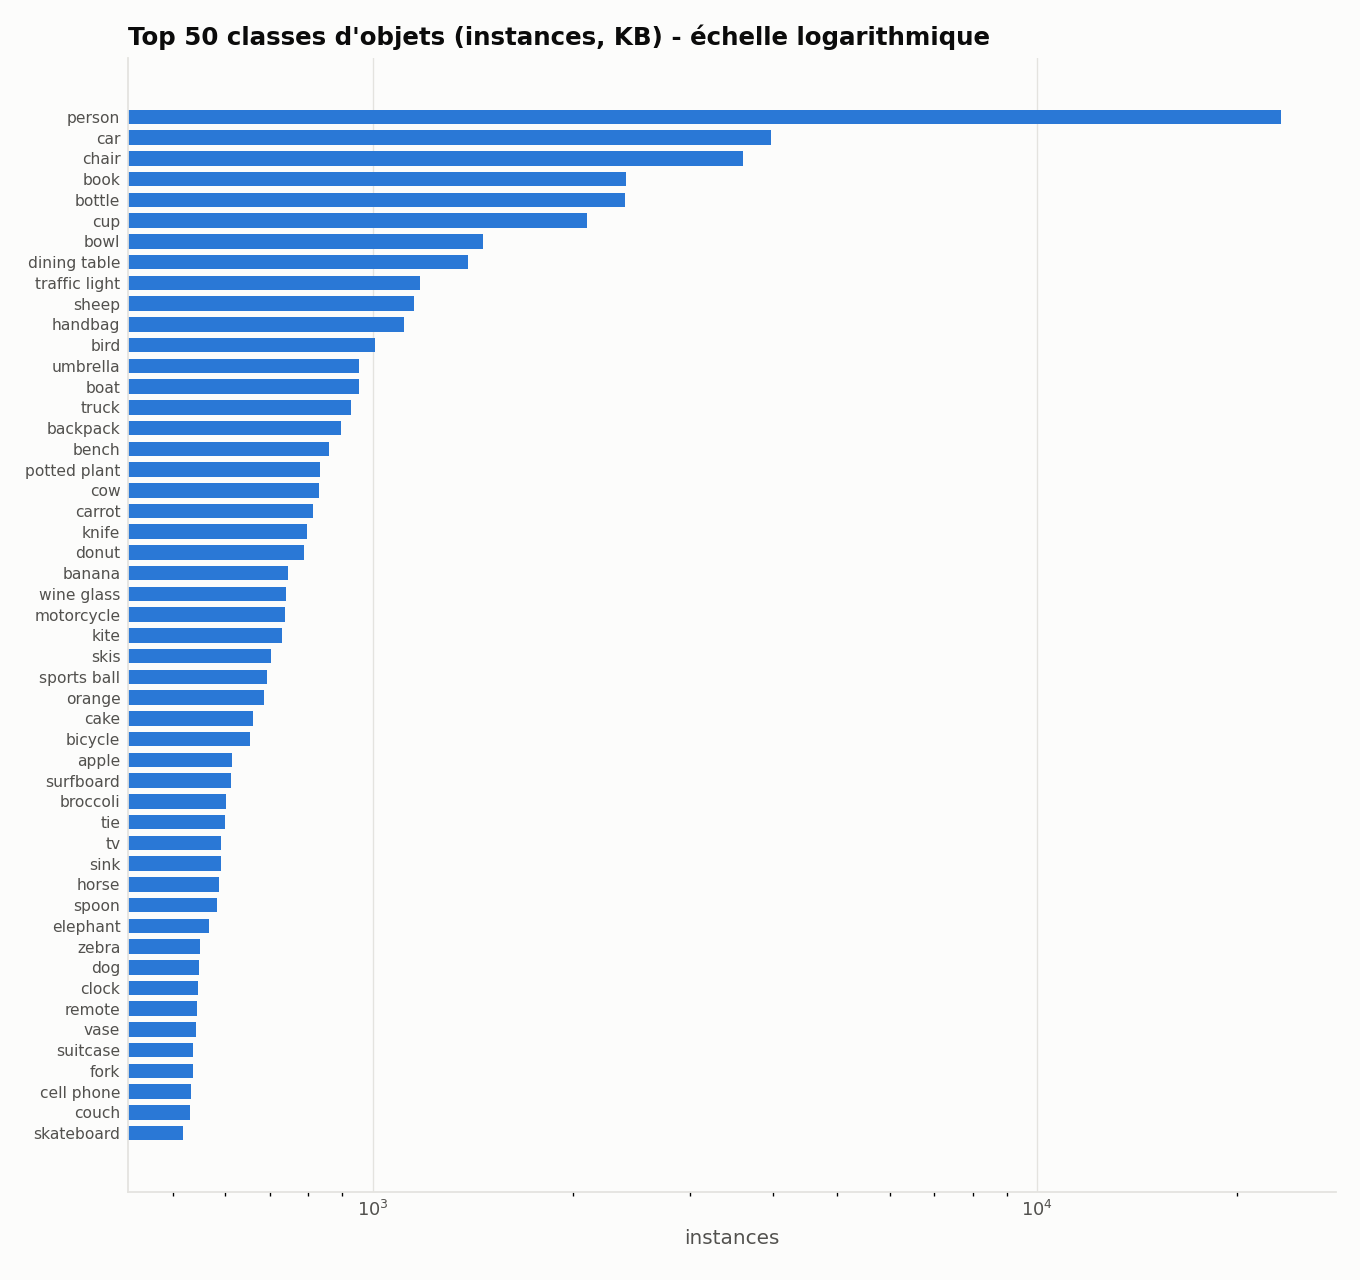

#### 02_scene_complexity.png

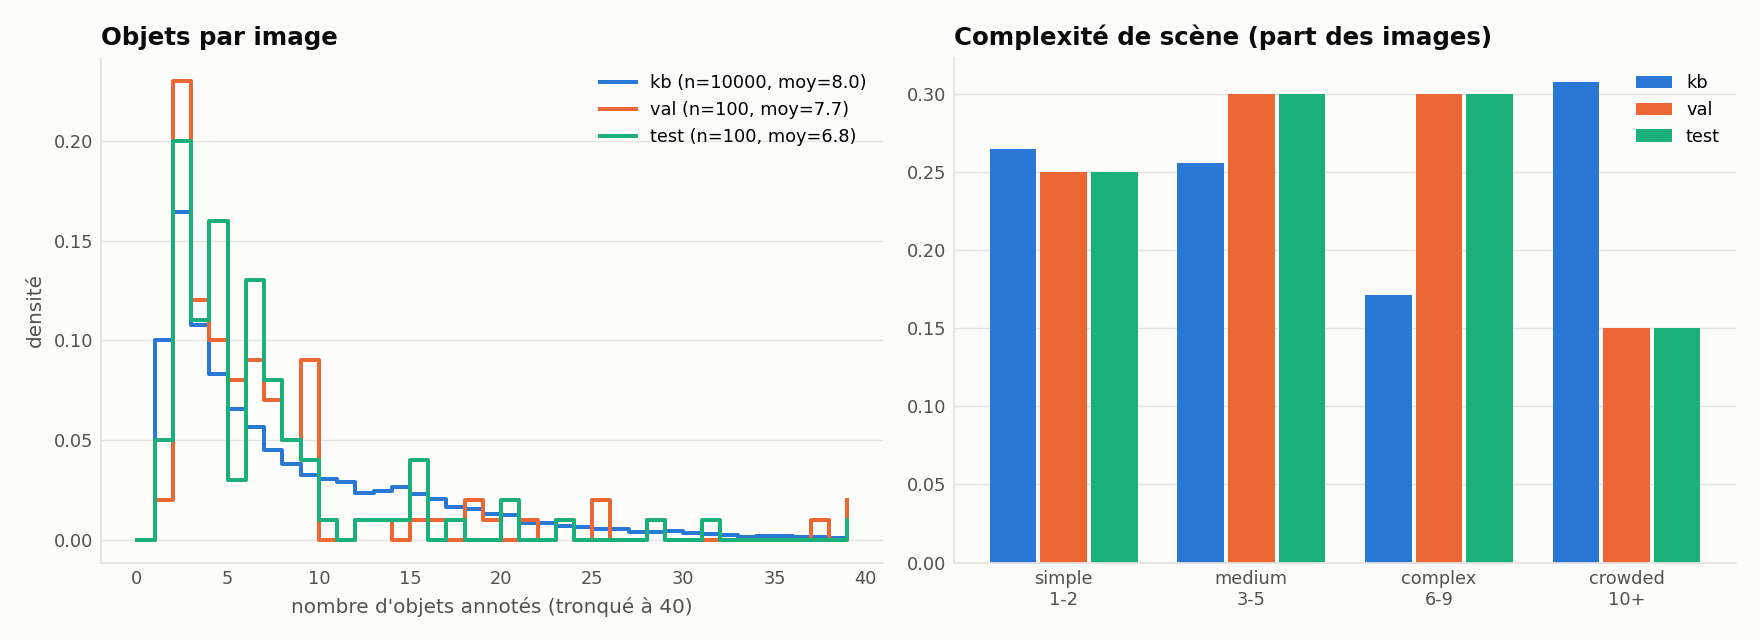

#### 03_spatial_relations.png

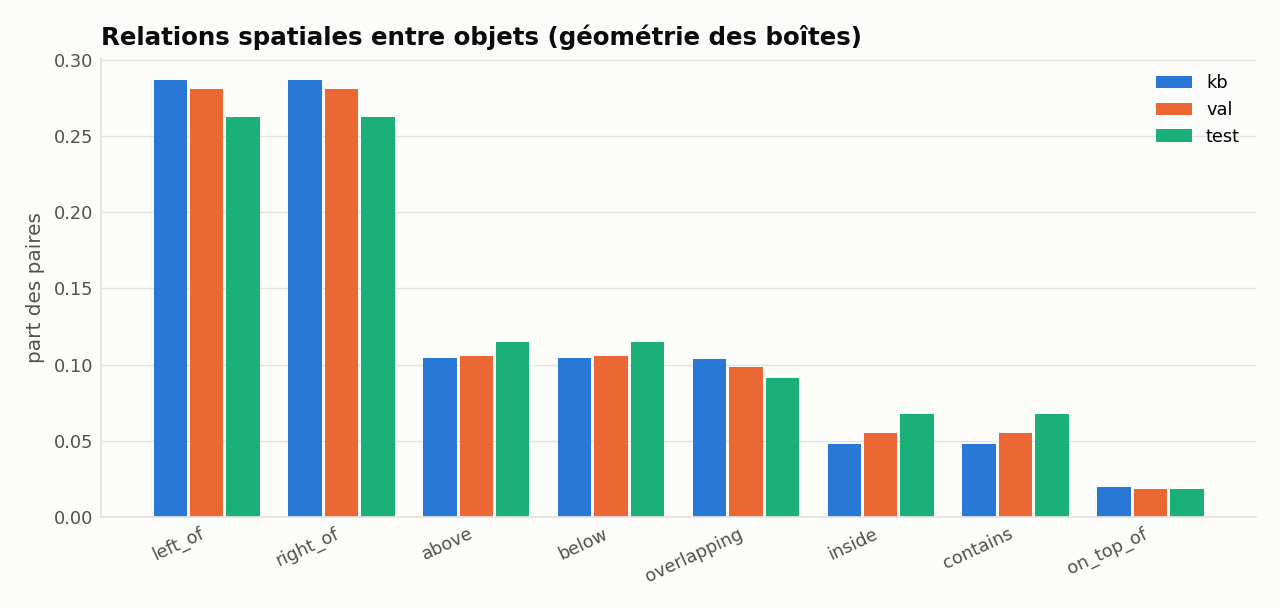

#### 04_caption_length_zipf.png

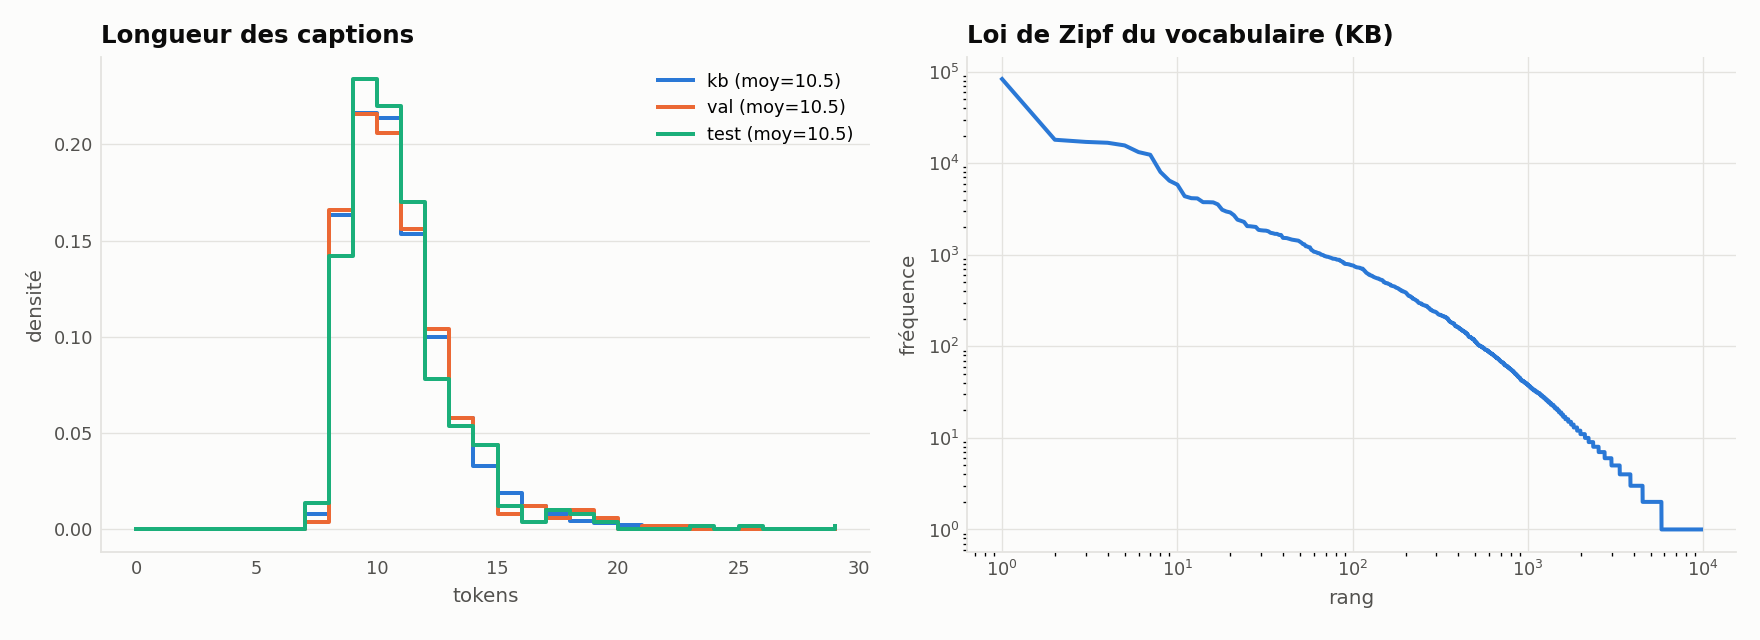

#### 05_pos_distribution.png

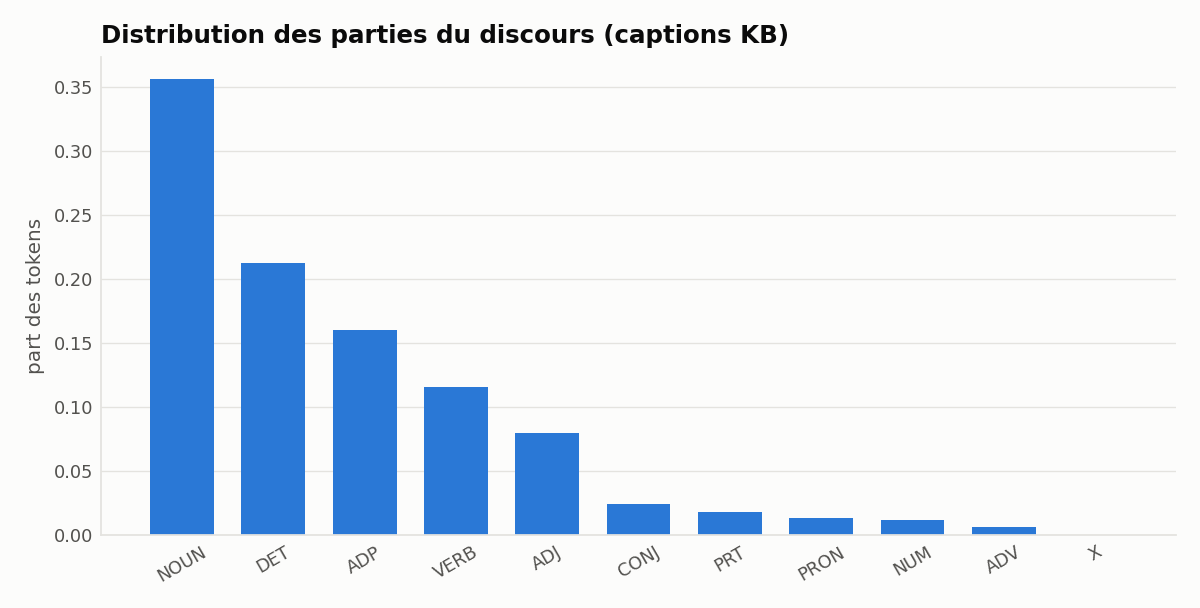

#### 06_cooccurrence_top30.png

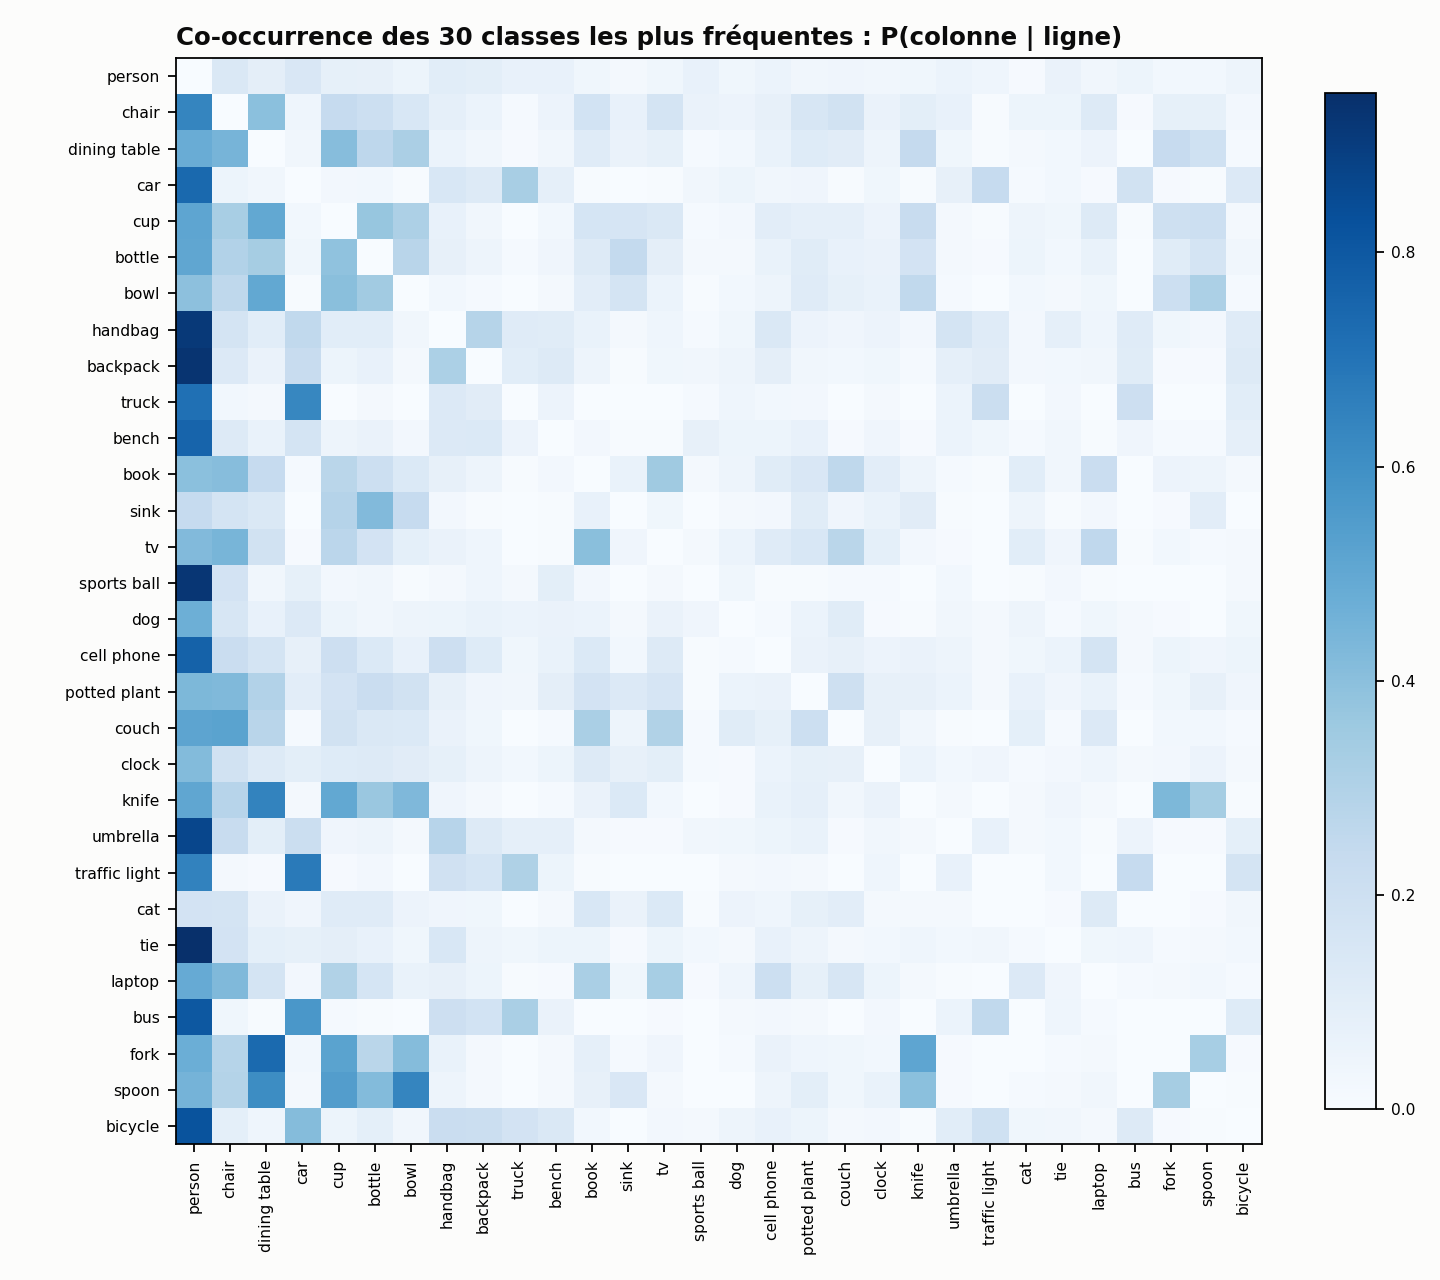

#### 07_objects_vs_caption_length.png

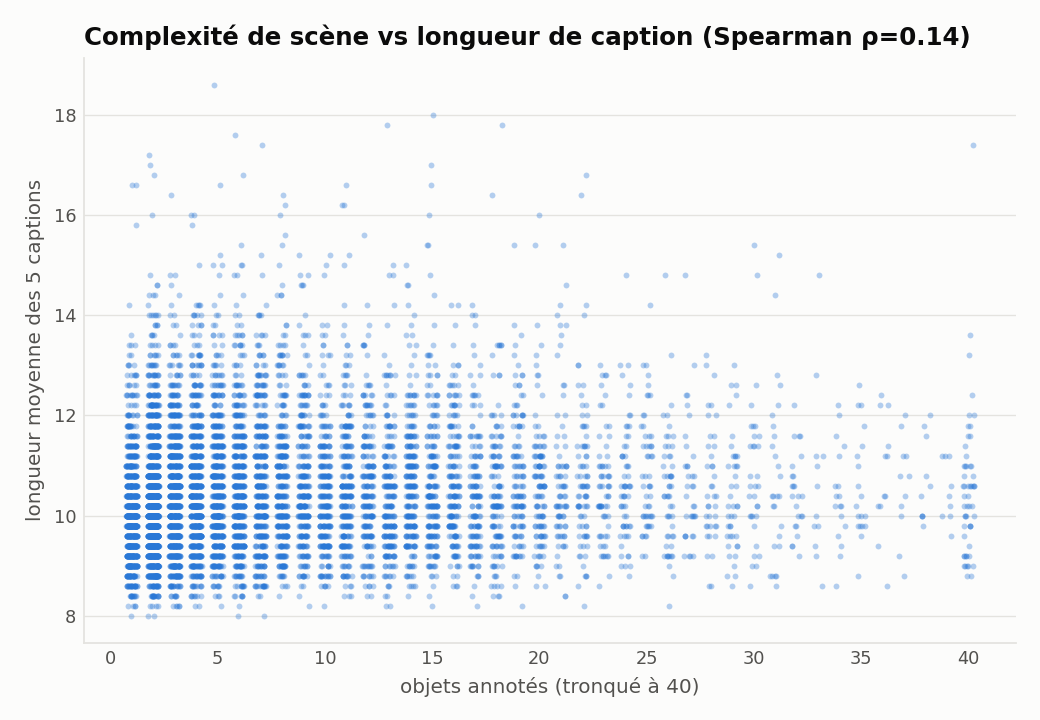

#### 08_diversity_context_light_size.png

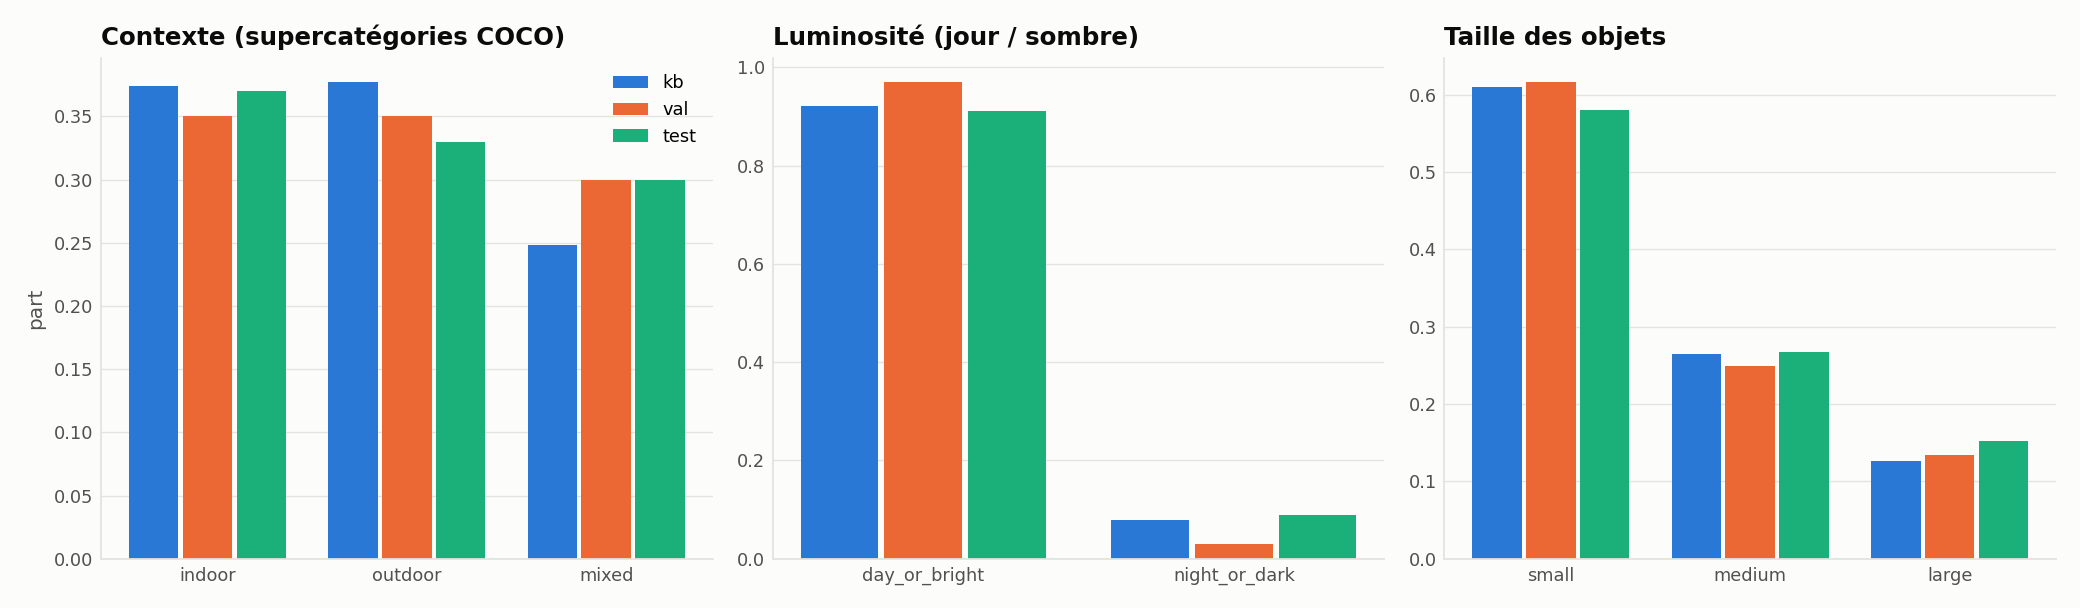

#### 09_dominant_colors.png

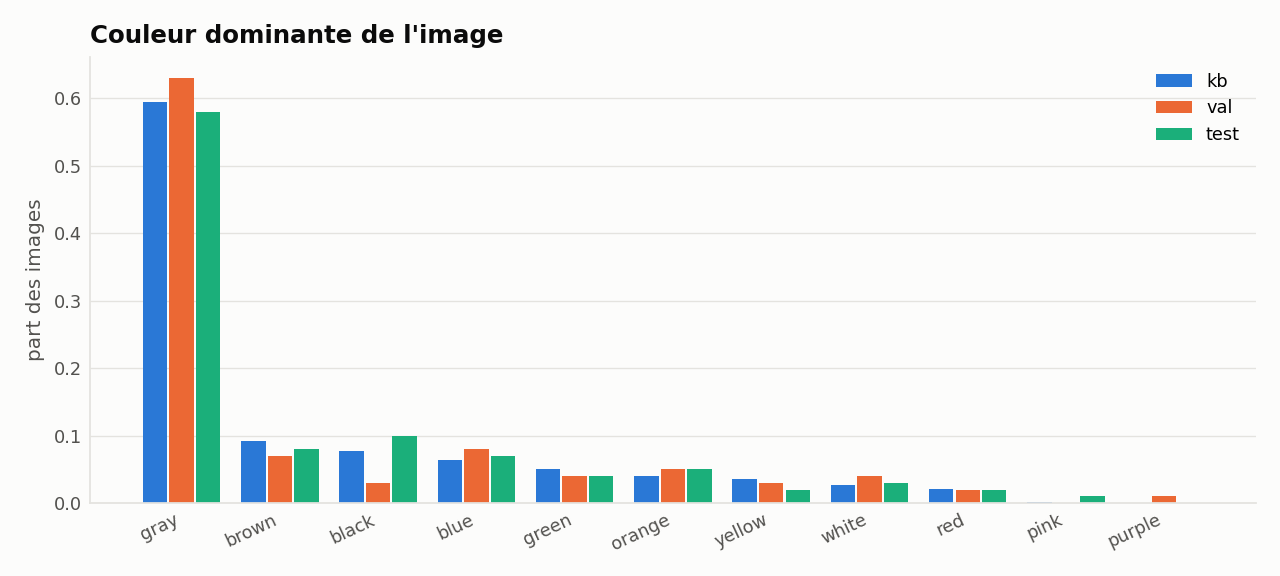

#### 10_sample_grid.png

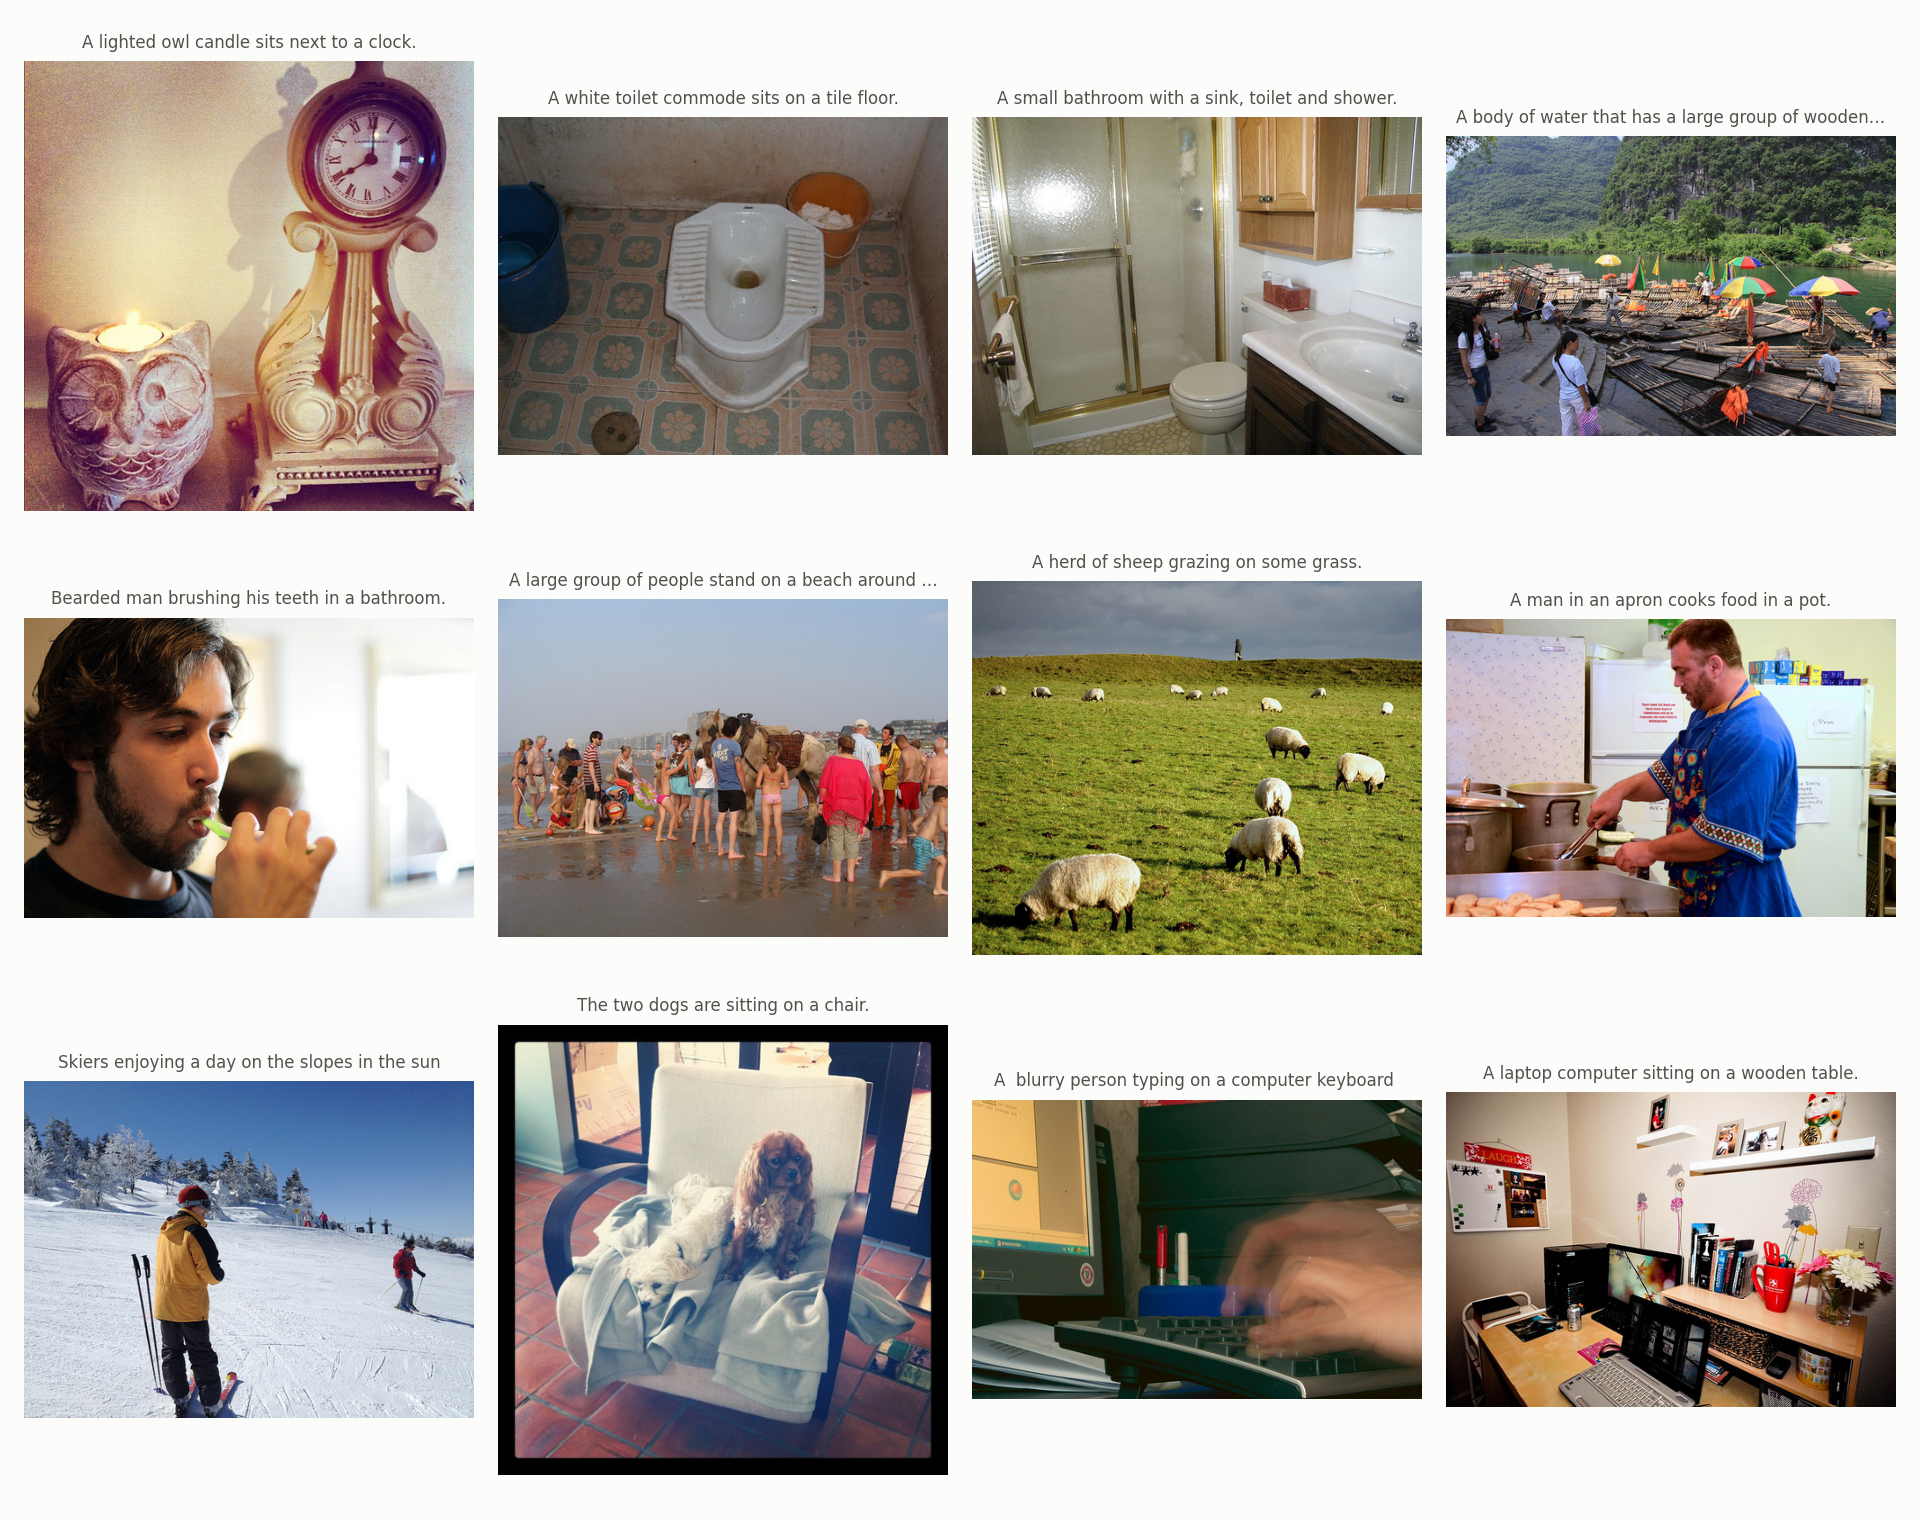

In [11]:
for f in sorted(P["eda"].glob("*.png")):
    display(Markdown(f"#### {f.name}")); display(Image(filename=str(f)))

In [12]:
import json, copy, re
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
from common import sha256_file
from rag_data import Release

art = Path("artifacts")
caps = [json.loads(l) for l in open(art / "tables/kb_captions.jsonl", encoding="utf-8") if l.strip()]

COLORS = ["white", "black", "red", "blue", "green", "brown", "yellow", "orange", "gray", "grey", "pink", "purple", "silver", "gold", "golden", "beige", "tan"]
SHAPES = ["round", "circular", "square", "rectangular", "triangular", "oval", "curved", "flat", "pointed", "spherical", "cylindrical"]

def count_words(words):
    occ, imgs = Counter(), {w: set() for w in words}
    for c in caps:
        toks = c["caption_clean"].split()
        for t in toks:
            if t in words:
                occ[t] += 1; imgs[t].add(c["image_id"])
    return {w: {"occurrences": occ[w], "images": len(imgs[w])} for w in words if occ[w] > 0}

col, shp = count_words(COLORS), count_words(SHAPES)
col = dict(sorted(col.items(), key=lambda kv: -kv[1]["occurrences"]))
shp = dict(sorted(shp.items(), key=lambda kv: -kv[1]["occurrences"]))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar(list(col), [v["occurrences"] for v in col.values()], color="#3b6fb6"); axs[0].set_title("Attributs de couleur (captions KB)", fontsize=10)
axs[1].bar(list(shp), [v["occurrences"] for v in shp.values()], color="#eb6834"); axs[1].set_title("Attributs de forme (captions KB)", fontsize=10)
for a in axs:
    a.tick_params(axis="x", rotation=60, labelsize=8); a.set_ylabel("occurrences")
plt.tight_layout()
png = art / "eda/11_attributs_couleur_forme.png"
fig.savefig(png, dpi=150); plt.show()

# stats.json
sp = art / "eda/stats.json"
S = json.loads(sp.read_text(encoding="utf-8"))
S["caption_attributes_kb"]["by_type"]["shape"] = sum(v["occurrences"] for v in shp.values())
S["attributs_couleur_forme_kb"] = {"couleur": col, "forme": shp, "source": "captions de la KB (lexique de mots)"}
sp.write_text(json.dumps(S, indent=2, ensure_ascii=False), encoding="utf-8")

# EDA_REPORT.md
rp = art / "eda/EDA_REPORT.md"
txt = rp.read_text(encoding="utf-8")
if "11_attributs_couleur_forme.png" not in txt:
    top_shapes = ", ".join(f"{k} ({v['occurrences']})" for k, v in list(shp.items())[:6])
    txt += ("\n\n## 8. Attributs de couleur et de forme (captions KB)\n\n![](11_attributs_couleur_forme.png)\n\n"
            f"Formes les plus fréquentes : {top_shapes}.\n")
    rp.write_text(txt, encoding="utf-8")

# manifest
mp = art / "manifest.json"
m = json.loads(mp.read_text(encoding="utf-8"))
ref = copy.deepcopy(m["files"]["eda/01_top50_classes.png"])
m["files"]["eda/11_attributs_couleur_forme.png"] = ref
for rel in ("eda/11_attributs_couleur_forme.png", "eda/stats.json", "eda/EDA_REPORT.md"):
    f = art / rel; info = m["files"][rel]
    info["sha256"] = sha256_file(f)
    for key in ("size", "bytes"):
        if key in info: info[key] = f.stat().st_size
m["n_files"] = len(m["files"])
mp.write_text(json.dumps(m, indent=2, ensure_ascii=False), encoding="utf-8")

print("formes :", {k: v["occurrences"] for k, v in shp.items()})
print("fichiers modifiés ou manquants :", Release("artifacts", "clip-b32").verify())

C:\Users\Cerine\AppData\Local\Temp\ipykernel_7792\34508720.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.savefig(png, dpi=150); plt.show()


formes : {'flat': 73, 'round': 57, 'square': 53, 'circular': 14, 'rectangular': 12, 'oval': 9, 'curved': 9, 'pointed': 9, 'cylindrical': 2, 'triangular': 1}
fichiers modifiés ou manquants : []
